# 02 · Audit de fuite de données et benchmark des modèles

Deuxième notebook de la série. Avant de surveiller un modèle, il faut être sûr qu'il a été
**correctement construit** : pas de fuite de données, un protocole de validation qui reproduit la
production, et une règle de sélection cohérente avec l'usage ALM. Tout est exécuté par le package
`alm_monitoring` ; le notebook appelle, montre, commente.

**Plan**

1. Découpe temporelle : référence 2013-2015, surveillance 2016-2017
2. Les quatre contrôles de fuite (`alm_monitoring.leakage`), sur les features de base **et** métier
3. Interpréter la validation adversariale : dérive ou fuite ?
4. Démonstration : provoquer volontairement une fuite
5. Benchmark des candidats (illustratif sur échantillon, puis résultats complets : deux jeux de features)
6. Règle de sélection du champion et primauté de la calibration en ALM
7. Lecture de la *model card* : la dégradation attendue du biais de niveau
8. Explicabilité du champion : importances, dépendances partielles, sens économique
9. Champion-challenger : le test A/B d'un modèle comportemental

In [1]:
import json
import warnings

warnings.filterwarnings("ignore")
import logging

logging.getLogger("alm_monitoring").setLevel(logging.WARNING)

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pio.renderers.default = "notebook+png"  # +png : figure statique visible sur GitHub
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 140)

from alm_monitoring.data import lending_club as lc
from alm_monitoring import leakage
from alm_monitoring.modeling import run_benchmark, select_champion, benchmark_table

ROOT = ".."

## 1. Découpe temporelle

Un modèle comportemental est utilisé **dans le futur** : la seule validation honnête est donc
*hors temps* (out-of-time). Le package découpe le jeu préparé en deux fenêtres strictement
ordonnées :

| fenêtre | période | rôle |
|---|---|---|
| référence | 2013-01 → 2015-12 | entraînement + scores hors-pli (validation croisée) |
| surveillance | 2016-01 → 2017-12 | jamais vue à l'entraînement ; 2016 sert de *holdout* pour choisir le champion, 2016-2017 pour le monitoring mensuel |

Pourquoi commencer en 2013 ? Avant, les volumes sont faibles et `mort_acc` n'est pas collectée.
Pourquoi s'arrêter en 2017 ? Parce que la cible à 12 mois doit être observable à la date d'arrêté
(mars 2019), et parce que 2018 est une cohorte partielle.

Un découpage aléatoire (train/test mélangés sur 2013-2017) aurait donné une AUC flatteuse mais
aurait masqué la dérive de niveau que nous allons voir.

In [2]:
cols = [
    "id",
    lc.TIMESTAMP,
    lc.TARGET,
    *lc.NUMERIC_FEATURES,
    *lc.CATEGORICAL_FEATURES,
    "earliest_cr_line",
]
df = pd.read_parquet(f"{ROOT}/data/raw/lending_club_prepared.parquet", columns=cols)
# Features dérivées métier (ratios d'effort, écart au taux de marché du mois, ancienneté
# de crédit...) : toutes connues à l'émission, calculées par le package.
df = lc.engineer_features(df)
reference, current = lc.split_reference_current(df)
del df

NUM_METIER = [*lc.NUMERIC_FEATURES, *lc.ENGINEERED_NUMERIC_FEATURES]
CAT_METIER = [*lc.CATEGORICAL_FEATURES, *lc.ENGINEERED_CATEGORICAL_FEATURES]
print(
    f"Référence    : {len(reference):>9,} prêts  {reference[lc.TIMESTAMP].min():%Y-%m} -> {reference[lc.TIMESTAMP].max():%Y-%m}"
    f"   taux de prepayment {reference[lc.TARGET].mean():.3f}"
)
print(
    f"Surveillance : {len(current):>9,} prêts  {current[lc.TIMESTAMP].min():%Y-%m} -> {current[lc.TIMESTAMP].max():%Y-%m}"
    f"   taux de prepayment {current[lc.TARGET].mean():.3f}"
)
print(
    f"Features     : {len(lc.NUMERIC_FEATURES) + len(lc.CATEGORICAL_FEATURES)} de base"
    f" + {len(lc.ENGINEERED_NUMERIC_FEATURES) + len(lc.ENGINEERED_CATEGORICAL_FEATURES)} métier"
    f" ({', '.join([*lc.ENGINEERED_NUMERIC_FEATURES, *lc.ENGINEERED_CATEGORICAL_FEATURES])})"
)

Référence    :   791,538 prêts  2013-01 -> 2015-12   taux de prepayment 0.134
Surveillance :   877,986 prêts  2016-01 -> 2017-12   taux de prepayment 0.164
Features     : 21 de base + 7 métier (loan_to_income, installment_to_income, rate_spread, credit_history_years, mort_acc_missing, term_x_rate, fico_band)


## 2. Les quatre contrôles de fuite

`leakage.audit` enchaîne quatre contrôles complémentaires :

| contrôle | question posée | sévérité si échec |
|---|---|---|
| `forbidden_columns` | une colonne post-octroi est-elle utilisée comme feature ? | critical |
| `temporal_split` | la référence précède-t-elle strictement la surveillance ? | critical |
| `single_feature_power` | une feature seule a-t-elle une AUC > 0,90 contre la cible ? | critical |
| `adversarial_validation` | un classifieur distingue-t-il référence et surveillance ? | warning au plus |

Les deux premiers sont structurels, les deux derniers sont statistiques et tournent sur un
**échantillon de 20 000 prêts** (ce qui suffit largement pour une AUC).

L'audit porte sur les **28 features candidates** : les 21 features de base et les 7 features
métier dérivées (`loan_to_income`, `installment_to_income`, `rate_spread`,
`credit_history_years`, `mort_acc_missing`, `term_x_rate`, `fico_band`). Une feature dérivée
peut introduire une fuite aussi sûrement qu'une colonne brute : elle passe donc les mêmes contrôles.

In [3]:
audit = leakage.audit(
    reference,
    current,
    target=lc.TARGET,
    timestamp=lc.TIMESTAMP,
    numeric_features=NUM_METIER,
    categorical_features=CAT_METIER,
    forbidden_columns=lc.POST_ORIGINATION_COLUMNS,
    sample_size=20_000,
)
print(audit.summary())
print("\nAudit réussi (aucun constat critique) :", audit.passed)

Audit de fuite : WARNING
- [ok] forbidden_columns: aucune colonne post-octroi parmi les features
- [ok] temporal_split: la référence précède strictement la surveillance
- [ok] single_feature_power: aucune feature ne sépare la cible à elle seule
- [warning] adversarial_validation: les fenêtres sont fortement séparables : dérive à documenter, fuite à exclure feature par feature (AUC adversariale = 0.947)

Audit réussi (aucun constat critique) : True


In [4]:
audit.to_dataframe()[["check", "severity", "message"]]

,check,severity,message
0,forbidden_columns,ok,aucune colonne post-octroi parmi les features
1,temporal_split,ok,la référence précède strictement la surveillance
2,single_feature_power,ok,aucune feature ne sépare la cible à elle seule
3,adversarial_validation,warning,les fenêtres sont fortement séparables : dériv...


In [5]:
print("AUC univariée des 5 features les plus liées à la cible (référence) :")
print(audit.findings[2].details["top_auc"])
print("\nFeatures qui distinguent le plus les deux fenêtres (validation adversariale) :")
print(audit.findings[3].details["top_features"])

AUC univariée des 5 features les plus liées à la cible (référence) :
{'loan_to_income': 0.5752, 'revol_util': 0.5639, 'installment_to_income': 0.5614, 'dti': 0.5516, 'total_acc': 0.5462}

Features qui distinguent le plus les deux fenêtres (validation adversariale) :
{'revol_util': 0.5742, 'total_acc': 0.5525, 'loan_to_income': 0.5438, 'purpose': 0.5405, 'installment_to_income': 0.5382}


## 3. Interpréter la validation adversariale

Le classifieur distingue référence et surveillance avec une **AUC adversariale d'environ 0,95**
sur l'échantillon ci-dessus (0,964 dans l'audit complet enregistré dans
`reports/leakage_audit_lending_club.json`, calculé sur les 28 features). Faut-il s'en alarmer ?

* Une **fuite** se manifesterait par une feature individuelle très prédictive de la cible
  (`single_feature_power`) ou par la présence d'une colonne post-octroi. Ici, la meilleure feature
  isolée (`loan_to_income`) n'a qu'une AUC de ~0,57 contre la cible et aucune colonne interdite n'est
  présente, ni parmi les features brutes ni parmi les features dérivées.
* Ce que le classifieur adversarial détecte, c'est une **dérive de population** : Lending Club a
  changé sa grille tarifaire (`int_rate` par `grade`), sa politique d'octroi (`dti`,
  `verification_status`, `purpose`, taux d'effort `loan_to_income`) et introduit les demandes
  conjointes. Pris ensemble, ces petits déplacements suffisent à dater un prêt, aucune feature
  n'étant isolément très discriminante (AUC univariées adversariales ≤ 0,58).
* Les features métier font légèrement **monter** l'AUC adversariale (0,92 avec les seules features
  de base) : les ratios d'effort résument plusieurs déplacements à la fois. Ce n'est pas une fuite,
  c'est une dérive mieux résumée ; le notebook 03 surveille d'ailleurs ces ratios chaque mois.

C'est pourquoi le package plafonne ce contrôle à **warning** : il documente une dérive à surveiller,
il n'arrête pas l'entraînement. On a d'ailleurs exclu volontairement `initial_list_status`
(`lc.OPERATIONAL_COLUMNS`) : un attribut purement opérationnel de la plateforme qui, à lui seul,
« datait » les prêts sans rien dire de l'emprunteur.

In [6]:
audit_complet = pd.read_json(f"{ROOT}/reports/leakage_audit_lending_club.json")
audit_complet[["check", "severity", "message"]]

,check,severity,message
0,forbidden_columns,ok,aucune colonne post-octroi parmi les features
1,temporal_split,ok,la référence précède strictement la surveillance
2,single_feature_power,ok,aucune feature ne sépare la cible à elle seule
3,adversarial_validation,warning,les fenêtres sont fortement séparables : dériv...


## 4. Démonstration : provoquer volontairement une fuite

Pour montrer que les contrôles ne sont pas décoratifs, on fabrique deux fuites classiques :

1. une feature **construite à partir de la cible** (par exemple un « nombre de mois actifs » qui ne
   serait connu qu'à la fin du prêt) : `check_single_feature_power` doit la repérer ;
2. l'ajout de `total_pymnt` (montant total remboursé, connu après coup) à la liste des features :
   `check_forbidden_columns` doit refuser.

In [7]:
rng = np.random.default_rng(42)
fuite = reference.sample(20_000, random_state=42).copy()
# Variable "mois_actifs_bruites" : révèle presque parfaitement la cible (fuite de type post-octroi)
fuite["mois_actifs_bruites"] = np.where(
    fuite[lc.TARGET] == 1, rng.uniform(1, 11, len(fuite)), rng.uniform(10, 60, len(fuite))
)
constat = leakage.check_single_feature_power(
    fuite,
    target=lc.TARGET,
    numeric_features=[*lc.NUMERIC_FEATURES, "mois_actifs_bruites"],
    sample_size=20_000,
)
print(f"[{constat.severity.value}] {constat.check}: {constat.message}")
print("features suspectes :", constat.details["suspicious"])

[critical] single_feature_power: 1 feature(s) séparent presque parfaitement la cible
features suspectes : {'mois_actifs_bruites': 0.999}


In [8]:
constat = leakage.check_forbidden_columns(
    [*NUM_METIER, *CAT_METIER, "total_pymnt"],
    lc.POST_ORIGINATION_COLUMNS,
)
print(f"[{constat.severity.value}] {constat.check}: {constat.message}")
print("colonnes refusées :", constat.details["columns"])

[critical] forbidden_columns: 1 feature(s) post-octroi détectée(s)
colonnes refusées : ['total_pymnt']


Dans le script d'entraînement (`scripts/train_lending_club.py`), un audit non réussi (`passed ==
False`) **interrompt l'entraînement** avec un code de retour non nul : le pipeline ne peut pas
produire un champion construit sur une fuite.

## 5. Benchmark des candidats

Trois candidats de complexité croissante, tous robustes aux valeurs manquantes :

* `naive_prior` : prédit le taux de base. Plancher : tout modèle doit le battre.
* `logistic_regression` : référence auditable (coefficients lisibles), appréciée en validation de
  modèles bancaire.
* `hist_gradient_boosting` : non linéaire, interactions automatiques, catégories natives.

Chaque candidat est évalué sur **deux jeux de features**, à protocole strictement identique :

* `base` : les 21 features brutes de l'octroi ;
* `engineered` : les mêmes plus les 7 features métier de `lc.engineer_features` (taux d'effort,
  écart au taux de marché du mois d'émission `rate_spread`, ancienneté de crédit, interaction
  durée × taux, classes FICO, indicateur de manquant informatif).

Protocole : entraînement sur la référence **uniquement**, scores de référence **hors-pli**
(validation croisée stratifiée), évaluation **hors temps** sur le *holdout* 2016. L'apport du
feature engineering se juge hors temps, jamais sur l'échantillon de développement.

### 5a. Version illustrative sur échantillon

Le benchmark complet (790 k prêts, 5 plis, deux jeux de features) prend plusieurs minutes. Pour que
le notebook reste rapide, on l'exécute ici sur **60 000 prêts de référence et 30 000 prêts hors
temps (2016), 3 plis, features de base uniquement**. Les ordres de grandeur sont les mêmes ; les
résultats complets, qui comparent les deux jeux de features, sont lus juste après.

In [9]:
holdout = current[current[lc.TIMESTAMP].dt.year == 2016]
ref_ech = reference.sample(60_000, random_state=42)
hold_ech = holdout.sample(30_000, random_state=42)

resultats_ech = run_benchmark(
    ref_ech,
    hold_ech,
    target=lc.TARGET,
    numeric_features=lc.NUMERIC_FEATURES,
    categorical_features=lc.CATEGORICAL_FEATURES,
    n_folds=3,
    feature_set="base",
)
benchmark_table(resultats_ech)

,auc_dev,auc_hors_temps,pr_auc_hors_temps,perte_auc,brier_hors_temps,log_loss_hors_temps,ece_hors_temps,biais_niveau_hors_temps
modele,,,,,,,,
naive_prior [base],0.5000,0.5000,0.1586,-0.0001,0.1341,0.4400,0.0255,-0.0255
logistic_regression [base],0.6282,0.6301,0.2364,-0.0031,0.1302,0.4255,0.0231,-0.0228
hist_gradient_boosting [base],0.6275,0.6280,0.2377,-0.0009,0.1301,0.4256,0.0218,-0.0217


In [10]:
champion_ech, raison_ech = select_champion(resultats_ech)
print("Champion (échantillon) :", champion_ech.label)
print("Justification          :", raison_ech)

Champion (échantillon) : hist_gradient_boosting [base]
Justification          : meilleur score de Brier hors temps (0.1301) parmi les 2 candidat(s) dont l'ECE reste sous 0.025


### 5b. Résultats complets

Le fichier `reports/benchmark_lending_club.json` contient les métriques du benchmark complet
(791 538 prêts de référence, 434 407 prêts hors temps, 5 plis) pour **cinq entrées** : le modèle
naïf, puis la logistique et le gradient boosting sur chacun des deux jeux de features. Chaque
entrée garde la liste exacte de ses features et, hors temps, la **PR-AUC** (*average precision*),
plus parlante que l'AUC quand la classe positive ne pèse que 15 %. Différences avec l'illustration
ci-dessus : davantage de données donc des écarts entre candidats plus nets, et des temps d'exécution
incompatibles avec un notebook de démonstration.

In [11]:
with open(f"{ROOT}/reports/benchmark_lending_club.json") as f:
    bench = json.load(f)

complet = (
    pd.DataFrame(
        [
            {
                "modele": r["name"],
                "jeu de features": r["feature_set"],
                "n_features": len(r["features"]),
                "auc_dev": r["in_time"]["auc"],
                "auc_hors_temps": r["out_of_time"]["auc"],
                "pr_auc_hors_temps": r["out_of_time"]["average_precision"],
                "perte_auc": r["auc_decay"],
                "brier_hors_temps": r["out_of_time"]["brier"],
                "log_loss_hors_temps": r["out_of_time"]["log_loss"],
                "ece_hors_temps": r["out_of_time"]["calibration_error"],
                "biais_niveau_hors_temps": r["out_of_time"]["level_bias"],
            }
            for r in bench
        ]
    )
    .set_index(["modele", "jeu de features"])
    .round(4)
)
print(
    f"Référence : {bench[0]['in_time']['rows']:,.0f} prêts | hors temps (2016) : {bench[0]['out_of_time']['rows']:,.0f} prêts"
    f" | taux observé hors temps : {bench[0]['out_of_time']['positive_rate']:.3f}"
)
complet

Référence : 791,538 prêts | hors temps (2016) : 434,407 prêts | taux observé hors temps : 0.156


,,n_features,auc_dev,auc_hors_temps,pr_auc_hors_temps,perte_auc,brier_hors_temps,log_loss_hors_temps,ece_hors_temps,biais_niveau_hors_temps
modele,jeu de features,,,,,,,,,
naive_prior,base,21,0.5000,0.5000,0.1559,-0.0000,0.1321,0.4349,0.0223,-0.0223
logistic_regression,base,21,0.6267,0.6245,0.2302,0.0035,0.1286,0.4216,0.0197,-0.0195
hist_gradient_boosting,base,21,0.6404,0.6393,0.2470,0.0018,0.1275,0.4180,0.0201,-0.0200
logistic_regression,engineered,28,0.6362,0.6291,0.2340,0.0110,0.1281,0.4202,0.0156,-0.0154
hist_gradient_boosting,engineered,28,0.6454,0.6412,0.2494,0.0065,0.1273,0.4173,0.0194,-0.0194


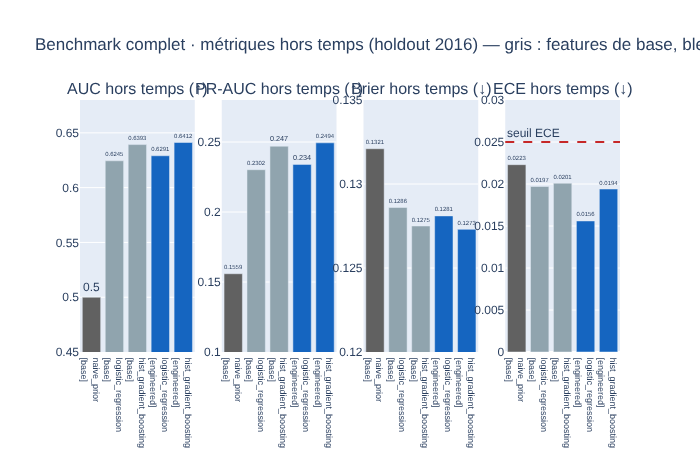

In [12]:
etiquettes = [f"{m}<br>[{fs}]" for m, fs in complet.index]
couleurs = {"base": "#90a4ae", "engineered": "#1565c0"}
marqueurs = ["#616161" if m == "naive_prior" else couleurs[fs] for m, fs in complet.index]
fig = make_subplots(
    rows=1,
    cols=4,
    subplot_titles=(
        "AUC hors temps (↑)",
        "PR-AUC hors temps (↑)",
        "Brier hors temps (↓)",
        "ECE hors temps (↓)",
    ),
)
for i, (col, seuil) in enumerate(
    [
        ("auc_hors_temps", None),
        ("pr_auc_hors_temps", None),
        ("brier_hors_temps", None),
        ("ece_hors_temps", 0.025),
    ],
    start=1,
):
    fig.add_trace(
        go.Bar(
            x=etiquettes,
            y=complet[col],
            marker_color=marqueurs,
            showlegend=False,
            text=complet[col].round(4),
            textposition="outside",
        ),
        row=1,
        col=i,
    )
    if seuil is not None:
        fig.add_hline(
            y=seuil,
            line={"dash": "dash", "color": "#c62828"},
            row=1,
            col=i,
            annotation_text="seuil ECE",
            annotation_position="top left",
        )
fig.update_yaxes(range=[0.45, 0.68], row=1, col=1)
fig.update_yaxes(range=[0.10, 0.28], row=1, col=2)
fig.update_yaxes(range=[0.12, 0.135], row=1, col=3)
fig.update_yaxes(range=[0, 0.03], row=1, col=4)
fig.update_xaxes(tickfont={"size": 9})
fig.update_layout(
    title="Benchmark complet · métriques hors temps (holdout 2016) — gris : features de base, bleu : features métier",
    height=460,
)
fig.show()

**Lecture.**

* L'AUC hors temps est de **0,64** pour le gradient boosting et **0,62-0,63** pour la logistique :
  un comportement de remboursement anticipé reste **peu prévisible** à l'octroi (pas de données de
  marché ni d'événements de vie). C'est normal et c'est pour cela que les seuils de monitoring sont
  ancrés sur ces valeurs plutôt que sur un « AUC ≥ 0,75 » générique. La PR-AUC (0,23-0,25 contre un
  plancher de 0,156, le taux de base) dit la même chose : le modèle concentre bien les remboursements
  anticipés dans les scores élevés, sans les isoler.
* La **perte d'AUC** entre développement et hors temps reste faible (≤ 0,011) : le classement des
  prêts est stable dans le temps. Elle est un peu plus marquée avec les features métier, dont
  `rate_spread` dépend du niveau des taux du mois.
* En revanche, les **cinq** entrées, y compris le modèle naïf, présentent un **biais de niveau hors
  temps de −1,5 à −2,2 points** : elles prédisent ~13,6-14 % de prepayment alors que 2016 en compte
  15,6 %. Ce n'est pas un défaut d'ajustement, c'est le niveau de la cible qui a bougé entre la
  référence et 2016.

**Apport du feature engineering.** Le gain est **modeste sur la discrimination et le Brier** : pour
le gradient boosting, AUC 0,639 → 0,641, PR-AUC 0,247 → 0,249, Brier 0,1275 → 0,1273. Il est surtout
visible **sur la calibration de la régression logistique** : l'ECE hors temps passe de 0,020 à
0,016 et le biais de niveau de −1,95 à −1,54 point, parce que les ratios d'effort et l'écart au
marché donnent au modèle linéaire des relations plus proches de la linéarité, là où le boosting les
reconstituait déjà seul. Tout ce qui a été testé est **conservé** dans le fichier de benchmark (les
cinq entrées, avec leurs listes de features), afin que la validation de modèles puisse retracer
pourquoi un jeu de features a été retenu et ce qu'aurait donné l'autre.

## 6. Règle de sélection du champion

`select_champion` applique une règle en deux temps, documentée dans `docs/methodologie_kpi.md` :

1. ne garder que les candidats (hors modèle naïf) dont l'**ECE hors temps ≤ 0,025** ;
2. parmi eux, retenir le **meilleur score de Brier hors temps** (à égalité, la meilleure AUC) ;
3. si aucun candidat n'est éligible, prendre le mieux calibré.

Pourquoi **la calibration prime en ALM** : l'output du modèle n'est pas une décision binaire
(« accepter / refuser ») mais une **probabilité agrégée en flux**. Le taux moyen prédit sur une
cohorte devient directement un taux d'écoulement dans le gap de taux et la projection de marge
d'intérêt. Un modèle qui classe parfaitement mais sur-estime de 3 points fausse le bilan projeté ;
un modèle un peu moins discriminant mais bien calibré donne des flux justes. Le score de Brier est
retenu comme critère final parce qu'il combine les deux (calibration + raffinement).

In [13]:
print("Règle appliquée dans le benchmark complet :")
carte = json.load(open(f"{ROOT}/data/processed/lending_club/model_card.json"))
print("  champion         :", f"{carte['champion']} [{carte['champion_feature_set']}]")
print("  nb de features   :", len(carte["champion_features"]))
print("  justification    :", carte["selection_rule"])
print()
print(
    "Sur l'échantillon illustratif (features de base), la même règle donne :", champion_ech.label
)

Règle appliquée dans le benchmark complet :
  champion         : hist_gradient_boosting [engineered]
  nb de features   : 28
  justification    : meilleur score de Brier hors temps (0.1273) parmi les 4 candidat(s) dont l'ECE reste sous 0.025

Sur l'échantillon illustratif (features de base), la même règle donne : hist_gradient_boosting [base]


Remarque : le seuil d'ECE de 0,025 laisse les quatre candidats non naïfs éligibles (ECE 0,0197 et
0,0201 pour les features de base, 0,0156 et 0,0194 pour les features métier) ; avec un seuil strict
de 0,02, le hasard des arrondis départagerait des modèles équivalents, d'où le choix d'une tolérance
de 0,025 documentée. L'écart de Brier en faveur du gradient boosting sur features métier est petit
(0,1273 contre 0,1275 pour le même modèle sur features de base et 0,1281 pour la logistique sur
features métier) : la régression logistique enrichie des features métier, mieux calibrée (ECE
0,016), resterait un choix défendable si la lisibilité des coefficients était prioritaire pour la
validation interne. C'est justement ce que la section 9 (champion-challenger) va tester sur les
fenêtres de production.

## 7. Lecture de la model card

La *model card* (`data/processed/lending_club/model_card.json`) fige ce que le modèle est censé
faire et dans quelles conditions : cible, jeu de features retenu (`champion_feature_set`) et liste
exacte des features (`champion_features`), colonnes interdites, périodes, métriques. Elle contient
désormais aussi les éléments d'explicabilité (`top_features`, `economic_sign_check`) et la décision
champion-challenger, lus dans les sections 8 et 9. Les métriques par année de surveillance annoncent
déjà ce que le monitoring mensuel va détailler.

In [14]:
groupes = carte["features"]
pd.DataFrame(
    {
        "groupe": list(groupes),
        "n": [len(v) for v in groupes.values()],
        "features": [", ".join(v) for v in groupes.values()],
    }
).set_index("groupe")

,n,features
groupe,,
base_numeric,16,"loan_amnt, term_months, int_rate, installment,..."
base_categorical,5,"grade, home_ownership, purpose, verification_s..."
engineered_numeric,6,"loan_to_income, installment_to_income, rate_sp..."
engineered_categorical,1,fico_band


In [15]:
par_annee = pd.DataFrame(
    {
        "référence (hors-pli)": carte["metrics"]["reference_out_of_fold"],
        "2016 (hors temps)": carte["metrics"]["current_by_year"]["2016"],
        "2017": carte["metrics"]["current_by_year"]["2017"],
    }
).T[
    ["rows", "positive_rate", "mean_prediction", "level_bias", "auc", "brier", "calibration_error"]
]
par_annee.round(4)

,rows,positive_rate,mean_prediction,level_bias,auc,brier,calibration_error
référence (hors-pli),791538.0,0.1336,0.1335,-0.0001,0.6454,0.1119,0.0010
2016 (hors temps),434407.0,0.1559,0.1365,-0.0194,0.6412,0.1273,0.0194
2017,443579.0,0.1718,0.1388,-0.0330,0.6419,0.1379,0.0330


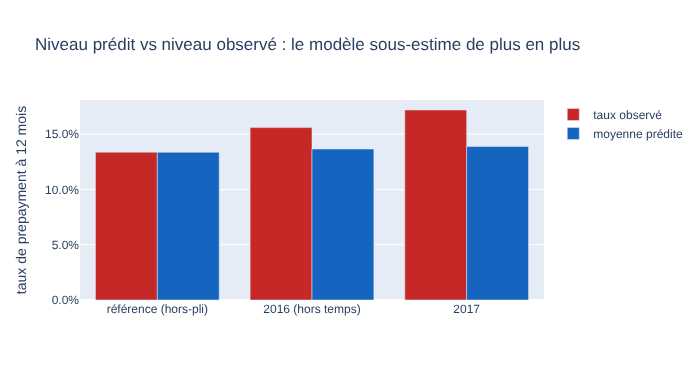

In [16]:
fig = go.Figure()
fig.add_trace(
    go.Bar(
        name="taux observé",
        x=par_annee.index,
        y=par_annee["positive_rate"],
        marker_color="#c62828",
    )
)
fig.add_trace(
    go.Bar(
        name="moyenne prédite",
        x=par_annee.index,
        y=par_annee["mean_prediction"],
        marker_color="#1565c0",
    )
)
fig.update_layout(
    barmode="group",
    title="Niveau prédit vs niveau observé : le modèle sous-estime de plus en plus",
    yaxis={"tickformat": ".1%", "title": "taux de prepayment à 12 mois"},
    height=380,
)
fig.show()

**Lecture.** L'AUC est quasi identique sur les trois périodes (0,645 → 0,641 → 0,642) : le modèle
**classe** toujours aussi bien. Mais la moyenne prédite reste collée au niveau de la référence
(~13,7-13,9 %) alors que le taux observé passe à 15,6 % puis **17,2 %** : le **biais de niveau** se
creuse de −1,9 à **−3,3 points**, l'ECE passe de 0,0010 (hors-pli) à 0,033 et le Brier se dégrade
d'environ 8 % entre 2016 et 2017 (0,127 → 0,138).

En termes ALM : à partir de 2017, le modèle **sous-estime l'écoulement anticipé du portefeuille
d'environ un cinquième** (3,3 points sur 17 %). C'est exactement le type de dérive qu'un monitoring
limité à l'AUC n'aurait jamais vu. Le notebook 03 montre comment les KPIs mensuels la détectent et
quand.

## 8. Explicabilité du champion

Un modèle de boosting n'a pas de coefficients lisibles ; la validation de modèles demande pourtant
de savoir **ce qui pilote le score** et si le modèle raisonne **dans le bon sens économique**. Le
script d'entraînement produit trois artefacts, calculés **hors temps** (holdout 2016) :

* `reports/importance_lending_club.csv` : importance par permutation (dégradation de l'AUC quand on
  mélange une feature, moyenne et écart-type sur plusieurs répétitions) ;
* `reports/partial_dependence_lending_club.csv` : dépendance partielle, c'est-à-dire la probabilité
  moyenne prédite quand on force une feature à une valeur donnée, toutes choses égales par ailleurs ;
* `economic_sign_check` dans la model card : le sens de la dépendance partielle est confronté au
  sens attendu par la théorie du remboursement anticipé.

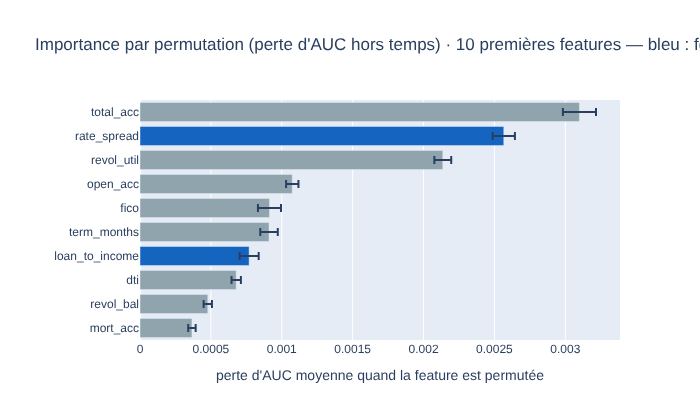

28 features évaluées ; 10 premières affichées.


In [17]:
importance = pd.read_csv(f"{ROOT}/reports/importance_lending_club.csv")
top10 = importance.head(10).iloc[::-1]
fig = go.Figure(
    go.Bar(
        x=top10["importance_moyenne"],
        y=top10["feature"],
        orientation="h",
        error_x={"type": "data", "array": top10["importance_ecart_type"]},
        marker_color=[
            "#1565c0"
            if f in lc.ENGINEERED_NUMERIC_FEATURES + lc.ENGINEERED_CATEGORICAL_FEATURES
            else "#90a4ae"
            for f in top10["feature"]
        ],
    )
)
fig.update_layout(
    title="Importance par permutation (perte d'AUC hors temps) · 10 premières features — bleu : features métier",
    xaxis_title="perte d'AUC moyenne quand la feature est permutée",
    height=420,
    margin={"l": 140},
)
fig.show()
print(f"{len(importance)} features évaluées ; 10 premières affichées.")

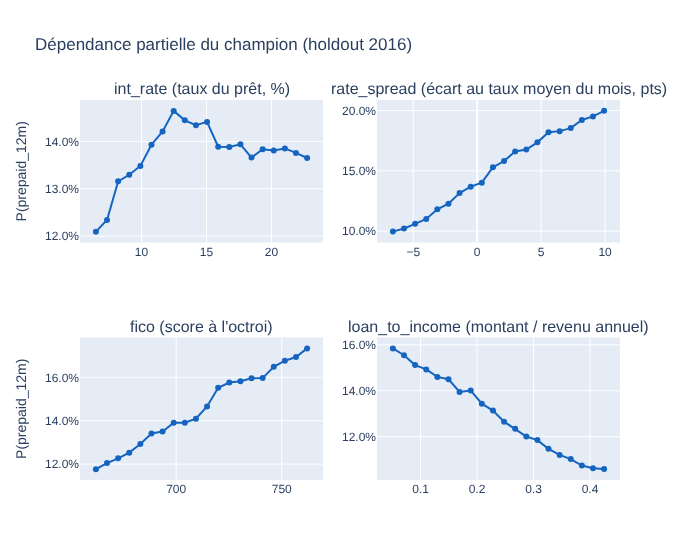

In [18]:
pdp = pd.read_csv(f"{ROOT}/reports/partial_dependence_lending_club.csv")
variables = ["int_rate", "rate_spread", "fico", "loan_to_income"]
libelles = {
    "int_rate": "int_rate (taux du prêt, %)",
    "rate_spread": "rate_spread (écart au taux moyen du mois, pts)",
    "fico": "fico (score à l'octroi)",
    "loan_to_income": "loan_to_income (montant / revenu annuel)",
}
fig = make_subplots(rows=2, cols=2, subplot_titles=[libelles[v] for v in variables])
for k, v in enumerate(variables):
    d = pdp[pdp["feature"] == v].sort_values("valeur")
    fig.add_trace(
        go.Scatter(
            x=d["valeur"],
            y=d["probabilite_moyenne"],
            mode="lines+markers",
            name=v,
            line={"color": "#1565c0"},
            showlegend=False,
        ),
        row=k // 2 + 1,
        col=k % 2 + 1,
    )
fig.update_yaxes(tickformat=".1%", title_text="P(prepaid_12m)", col=1)
fig.update_yaxes(tickformat=".1%", col=2)
fig.update_layout(title="Dépendance partielle du champion (holdout 2016)", height=560)
fig.show()

In [19]:
signes = pd.DataFrame(carte["economic_sign_check"])
print("Signes économiques conformes :", int(signes["conforme"].sum()), "/", len(signes))
signes

Signes économiques conformes : 3 / 3


,feature,attendu,observe,conforme
0,int_rate,croissant,croissant,True
1,rate_spread,croissant,croissant,True
2,fico,croissant,croissant,True


**Lecture.**

* Les features les plus influentes mêlent **profil de crédit** (`total_acc`, `revol_util`,
  `open_acc`, `fico`, `dti`) et **tarification** : `rate_spread`, la feature métier construite
  comme écart entre le taux du prêt et le taux moyen des prêts émis le même mois, arrive en
  **deuxième position**, devant `int_rate` brut. C'est le résultat attendu d'un modèle de
  remboursement anticipé : ce n'est pas le taux absolu qui pousse à refinancer, c'est le taux
  **relatif au marché**. `loan_to_income` figure aussi dans les dix premières.
* Les importances absolues sont faibles (quelques millièmes d'AUC) : aucune feature ne porte le
  modèle à elle seule, ce qui est cohérent avec l'audit de fuite (`single_feature_power`) et avec
  une AUC globale de 0,64.
* Les dépendances partielles sont **monotones croissantes** pour `int_rate`, `rate_spread` et
  `fico` : plus le prêt est cher (en absolu et par rapport au marché), plus la probabilité de
  remboursement anticipé est élevée ; plus l'emprunteur est solvable (FICO élevé), plus il a de
  facilité à refinancer. Les **trois signes attendus sont conformes**. `loan_to_income` est
  décroissante : un prêt lourd par rapport au revenu se refinance moins facilement.

Un **signe inverse** (par exemple une probabilité de remboursement anticipé qui baisserait quand le
`rate_spread` augmente) **bloquerait la mise en production**, quelle que soit la performance
hors temps : un modèle qui « gagne » des points d'AUC en exploitant une corrélation contre-intuitive
exploite probablement un artefact de la période de référence et se retournera dès que les taux
bougeront. C'est le contrôle que la validation de modèles et le métier ALM peuvent lire sans aucune
connaissance du boosting.

## 9. Champion-challenger

Le benchmark a départagé les candidats sur **un seul** jeu hors temps (2016). Avant de remplacer un
modèle en production, ou pour confirmer qu'on a eu raison de retenir le champion, on fait tourner un
**challenger en parallèle** sur les fenêtres mensuelles de surveillance et on compare, fenêtre par
fenêtre, les métriques qui comptent. C'est l'**équivalent du test A/B pour un modèle
comportemental** : on ne peut pas randomiser des emprunteurs, mais on peut scorer les mêmes prêts
avec deux modèles et regarder lequel se serait trompé le moins, mois après mois.

Ici le challenger est **le meilleur modèle sans features métier** (gradient boosting sur features de
base). La question posée : les features métier apportent-elles quelque chose *en production*, pas
seulement sur le holdout ?

La règle de décision (`alm_monitoring.modeling.challenger.decide`) est écrite à l'avance :

* **promouvoir** le challenger s'il améliore le Brier sur **au moins 2/3 des fenêtres** *et* ne
  dégrade pas l'erreur de calibration en moyenne ;
* **rejeter** s'il est moins bon sur le Brier dans la **majorité** des fenêtres ;
* sinon **indéterminé** : on prolonge la période d'observation.

24 fenêtres mensuelles comparées (2016-01 -> 2017-12)
Décision : REJETER | Brier dégradé sur 79% des 24 fenêtres
Part des fenêtres où le challenger a un meilleur Brier : 20.8% | delta Brier moyen : +0.00021 | delta calibration moyen : -0.00016


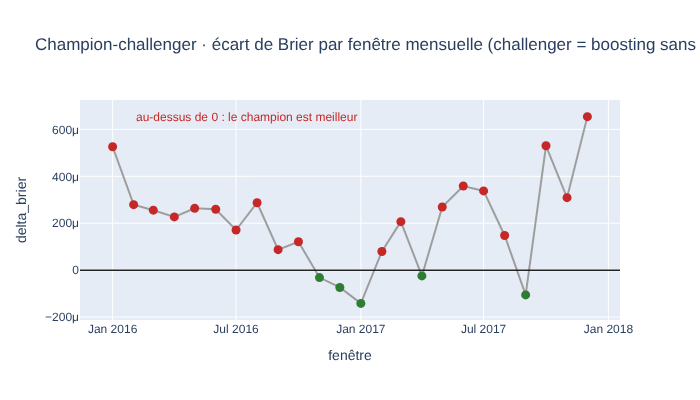

In [20]:
cc = pd.read_csv(
    f"{ROOT}/reports/champion_challenger_lending_club.csv", parse_dates=["window_start"]
)
decision = carte["champion_challenger"]
print(
    f"{len(cc)} fenêtres mensuelles comparées ({cc['window_start'].min():%Y-%m} -> {cc['window_start'].max():%Y-%m})"
)
print("Décision :", decision["decision"].upper(), "|", decision["reason"])
print(
    f"Part des fenêtres où le challenger a un meilleur Brier : {decision['share_better_brier']:.1%}"
    f" | delta Brier moyen : {decision['mean_delta_brier']:+.5f}"
    f" | delta calibration moyen : {decision['mean_delta_calibration']:+.5f}"
)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=cc["window_start"],
        y=cc["delta_brier"],
        mode="lines+markers",
        name="delta_brier (challenger − champion)",
        marker={
            "color": ["#c62828" if d > 0 else "#2e7d32" for d in cc["delta_brier"]],
            "size": 9,
        },
        line={"color": "#9e9e9e"},
    )
)
fig.add_hline(y=0, line={"color": "#212121", "width": 1.5})
fig.add_annotation(
    x=cc["window_start"].iloc[1],
    y=cc["delta_brier"].max(),
    text="au-dessus de 0 : le champion est meilleur",
    showarrow=False,
    xanchor="left",
    font={"color": "#c62828"},
)
fig.update_layout(
    title="Champion-challenger · écart de Brier par fenêtre mensuelle (challenger = boosting sans features métier)",
    yaxis_title="delta_brier",
    xaxis_title="fenêtre",
    height=400,
)
fig.show()

In [21]:
cc.assign(mois=cc["window_start"].dt.strftime("%Y-%m")).set_index("mois")[
    [
        "rows",
        "auc_champion",
        "auc_challenger",
        "brier_champion",
        "brier_challenger",
        "calibration_champion",
        "calibration_challenger",
        "delta_brier",
        "delta_calibration",
    ]
].round(4)

,rows,auc_champion,auc_challenger,brier_champion,brier_challenger,calibration_champion,calibration_challenger,delta_brier,delta_calibration
mois,,,,,,,,,
2016-01,32366,0.6477,0.6406,0.1152,0.1157,0.0046,0.0097,0.0005,0.0051
2016-02,39529,0.6379,0.6324,0.1124,0.1127,0.0041,0.0072,0.0003,0.0031
2016-03,61992,0.6420,0.6387,0.1148,0.1151,0.0083,0.0120,0.0003,0.0037
2016-04,36432,0.6434,0.6410,0.1131,0.1133,0.0027,0.0069,0.0002,0.0041
2016-05,28403,0.6408,0.6374,0.1160,0.1162,0.0073,0.0106,0.0003,0.0033
2016-06,33019,0.6343,0.6339,0.1297,0.1299,0.0171,0.0225,0.0003,0.0054
2016-07,34696,0.6392,0.6367,0.1327,0.1328,0.0249,0.0232,0.0002,-0.0017
2016-08,36280,0.6313,0.6267,0.1368,0.1371,0.0301,0.0281,0.0003,-0.0021
2016-09,28144,0.6485,0.6451,0.1424,0.1425,0.0347,0.0311,0.0001,-0.0036


**Lecture.** Le challenger (sans features métier) est **moins bon sur le Brier dans 79 % des 24
fenêtres** (19 sur 24) : il est donc **rejeté**, et le choix du champion avec features métier est
confirmé en conditions de production. Les écarts sont petits (quelques dix-millièmes de Brier),
cohérents avec le gain modeste vu au benchmark ; mais ils sont **systématiques** et de même signe
sur presque toute la période, ce que la règle « 2/3 des fenêtres » est précisément conçue pour
capter au lieu d'une moyenne qu'une fenêtre atypique pourrait fausser. La calibration est, en
moyenne, légèrement meilleure pour le challenger (delta négatif) : si la décision avait été prise sur
ce seul critère, elle aurait été inverse, d'où l'intérêt d'une règle écrite qui hiérarchise les
critères (Brier d'abord, calibration en garde-fou).

En pratique, cette table est le dataset que le scénario Dataiku alimenterait chaque mois quand un
modèle recalibré ou ré-estimé (notebook 03, section 6) est proposé comme challenger du champion en
place : la décision de bascule se lit dans la model card, avec sa justification chiffrée, et non dans
une impression sur une courbe.